# Reproduce Study 1

The main analysis dataset is [data/regression_data.csv](../data/regression_data.csv), and the main Python analysis script is [run.py](run.py). This notebook runs the same analysis with short explanations. Install `../requirements.txt`, then choose **Run all**.

This notebook loads the main data, prepares the comparison datasets, runs the analyses, and displays the paper's tables and empirical figure. No API key or original computer path is needed.

The primary calculation uses `payoff > RV`, stored in every payoff cell separately from source instructions. Script and Notebook both rebuild and check the primary inputs, then run the inclusive `>= RV` comparison, six source-bound cases and 123 point scenarios for Table C5. The active catalogue has 97 numerical records and three conditional Northcraft records. Set `check_reservations=False` to run the main tables and checks without the supplementary cases.


In [1]:
from pathlib import Path
from tempfile import TemporaryDirectory
import sys
import json
import pandas as pd
from IPython.display import display, Markdown, Image

# Work when the notebook is opened in scripts/ or in the main folder.
repository = Path.cwd()
if not (repository / "data").is_dir():
    repository = repository.parent
if not (repository / "data").is_dir():
    raise FileNotFoundError("Please open the complete Study 1 folder, including data/ and scripts/.")
sys.path.insert(0, str(repository))

from scripts.supporting.prepare_data import build_data, prepare_analysis_data
from scripts.supporting.analysis import run_analysis
from scripts.supporting.original_main_analysis import run_original_main
from scripts.supporting.presentation import build_tables
from scripts.run import publish_files
from scripts.supporting.payoff_info import check_payoff_columns

main = pd.read_csv(repository / "data/regression_data.csv")
display(main.head())
print(f"Main dataset: {len(main)} observations.")


,observation_id,payoff_json,agreement_rate,negotiations,search_complexity,bargaining_zone_share,number_of_issues,number_of_parties,number_of_compatible_issues,automated_counterpart,non_unanimous_rule
0,SRU0286,"{""schema_version"":1,""calculation_rule"":{""numer...",0.860947,338.0,0.358343,0.371880,3.0,2.0,0.0,0.0,0.0
1,PET2025_2b,"{""schema_version"":1,""calculation_rule"":{""numer...",0.290926,1069.0,0.746711,0.050067,3.0,2.0,0.0,1.0,0.0
2,SRU0324,"{""schema_version"":1,""calculation_rule"":{""numer...",0.862853,1276.0,0.552923,0.058627,8.0,2.0,2.0,0.0,0.0
3,SRU0334,"{""schema_version"":1,""calculation_rule"":{""numer...",0.531915,47.0,0.557962,0.038717,8.0,2.0,2.0,0.0,0.0
4,SRU0343,"{""schema_version"":1,""calculation_rule"":{""numer...",0.980952,105.0,0.408730,0.056261,6.0,2.0,1.0,0.0,0.0


Main dataset: 140 observations.


## 1. Prepare the analysis datasets

We check the main dataset against `data/derived/component_evidence.csv`, which retains the conditions and their coding decisions. We combine conditions using negotiation counts when available and equal weights otherwise. The stricter comparison keeps only the conditions marked for strict inclusion. The combined-payoff comparison averages independent experiment outcomes that used the same payoff record.

These intermediate datasets are built below and saved in `data/derived/`. The [data guide](../data/README.md) explains the coding behind them. To also recalculate the structural measures from the coded payoff and outcome files, change `rebuild_from_coded_sources` below to `True`.


In [2]:
temporary = TemporaryDirectory(prefix="study1-notebook-")
working = Path(temporary.name)
rebuild_from_coded_sources = True
check_reservations = True  # False runs the main tables and checks only.
datasets = (build_data(repository, working) if rebuild_from_coded_sources
            else prepare_analysis_data(repository, working))
display(pd.DataFrame([{"Dataset": name, "Observations": len(frame)}
                      for name, frame in datasets.items()]))


,Dataset,Observations
0,main,140
1,strict,124
2,aggregate_main,100
3,aggregate_strict,81


## 2. Run the models and checks

The code fits the five models, repeats them with the stricter data, and runs the negotiation-count weighted and combined-payoff comparisons. Continuous predictors are standardized in each fit. The required resampling checks use 5,000 draws with fixed seeds; the omission checks remove one observation at a time. The original-registration appendix tests are also included.


In [3]:
check_payoff_columns(pd.read_csv(working / "regression_data.csv"))
run_analysis(datasets, working, draws=5000)
run_original_main(repository, working, draws=5000)
build_tables(repository, working)
publish_files(repository, working)
if check_reservations:
    from scripts.supporting.reservation_sensitivity import run_reservation_sensitivity
    run_reservation_sensitivity(repository)
results = repository / "results"
checks = results / "checks"
print("Saved the intermediate datasets in data/ and the results in results/.")


main: 140 observations


strict: 124 observations


aggregate_main: 100 observations


aggregate_strict: 81 observations


Reservation rule: inclusive_ge


main: 140 observations


... (31 outputs left out)

aggregate_main: 100 observations


aggregate_strict: 81 observations


Reservation-rule checks complete: inclusive case, six > bound cases and 123 point scenarios.


Saved the intermediate datasets in data/ and the results in results/.


## 3. Read the tables

Tables 1–3 contain the descriptive statistics, five main regression models, and robustness checks. Tables C1–C4 give the supplementary results. The same tables are saved as separate CSV files in `results/tables/`.


In [4]:
display(Markdown((results / "tables/README.md").read_text(encoding="utf-8")))


## Table 1. Descriptive statistics and correlations

| Variable | Mean | SD | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| 1. Agreement rate | .91 | .15 | — |  |  |  |  |  |  |  |
| 2. Search complexity | .09 | .21 | −.59*** | — |  |  |  |  |  |  |
| 3. Bargaining-zone size | .63 | .32 | .21* | −.70*** | — |  |  |  |  |  |
| 4. Number of issues | 5.71 | 1.99 | .17* | .04 | −.21* | — |  |  |  |  |
| 5. Number of parties | 2.09 | .36 | −.08 | −.11 | .09 | −.20* | — |  |  |  |
| 6. Compatible issues | .92 | .81 | .07 | .10 | −.34*** | .69*** | −.30*** | — |  |  |
| 7. Automated / AI counterpart | .01 | .08 | −.36*** | .26** | −.15 | −.12 | −.02 | −.10 | — |  |
| 8. Agreement without unanimity | .01 | .07 | −.01 | −.06 | .16 | −.15 | .51*** | −.17* | −.01 | — |

Note. N = 140 observations. Agreement rate and both structural measures are on 0–1 scales. Counts are shown in their original units and can be averages across conditions. The last two controls are proportions when an observation combines different conditions. SD = standard deviation. * p < .05. ** p < .01. *** p < .001. Correlations are descriptive.

## Table 2. Agreement rates predicted by search complexity and bargaining-zone size

| Predictor | (1)<br>Search complexity | (2)<br>+ controls | (3)<br>Both + controls | (4)<br>Bargaining zone | (5)<br>+ controls |
| --- | --- | --- | --- | --- | --- |
| Search complexity | −.086***<br>(.017)<br>p < .001 | −.081***<br>(.017)<br>p < .001 | −.125***<br>(.018)<br>p < .001 | — | — |
| Bargaining-zone size | — | — | −.066***<br>(.015)<br>p < .001 | .030<br>(.019)<br>p = .107 | .027<br>(.020)<br>p = .176 |
| Number of issues | — | .028*<br>(.013)<br>p = .037 | .029*<br>(.013)<br>p = .030 | — | .029*<br>(.013)<br>p = .025 |
| Number of parties | — | −.022*<br>(.009)<br>p = .022 | −.031***<br>(.009)<br>p < .001 | — | −.014<br>(.011)<br>p = .220 |
| Compatible issues | — | −.009<br>(.011)<br>p = .426 | −.029*<br>(.013)<br>p = .021 | — | −.008<br>(.013)<br>p = .534 |
| Automated / AI counterpart | — | −.350<br>SE unavailable | −.354<br>SE unavailable | — | −.549<br>SE unavailable |
| Agreement without unanimity | — | .106<br>(.201)<br>p = .597 | .237<br>(.185)<br>p = .202 | — | .060<br>(.224)<br>p = .788 |
| Observations | 140 | 140 | 140 | 140 | 140 |
| R² | .353 | .444 | .529 | .043 | .192 |
| Adjusted R² | .348 | .419 | .504 | .036 | .156 |

Note. The dependent variable is agreement rate (0–1). Entries are coefficients, with HC3 robust standard errors in parentheses and two-sided p values beneath. Continuous predictors and the three count controls are standardized; indicator controls retain their original scales. Every model includes a constant. — indicates that a predictor is not included or is constant in this sample. * p < .05. ** p < .01. *** p < .001. The automated-counterpart indicator identifies a single observation; its HC3 standard error and p value are unavailable. The other coefficients have estimable HC3 standard errors.

## Table 3. Confirmation and supplementary checks of the agreement-rate results

| Check | Data | N | Search-complexity coefficient or 95% interval | p value or omission count | R² | R² difference or 95% interval |
| --- | --- | --- | --- | --- | --- | --- |
| Strict inclusion | Strict | 124 | −.145 | p < .001 | .575 | .355<br>[.119, .450] |
| 5,000 observation resamples | Main | 140 | [−.177, −.063] | — | — | [.045, .398] |
| 5,000 observation resamples | Strict | 124 | [−.202, −.079] | — | — | [.119, .450] |
| Single-observation omissions | Main | 140 | [−.129, −.106] | 140/140 p < .05 | — | [.192, .290] |
| Single-observation omissions | Strict | 124 | [−.150, −.127] | 124/124 p < .05 | — | [.313, .381] |
| Negotiation-count weights (Model 6) | Main | 139 | −.119 | p < .001 | .820 | — |
| Weighted observation resamples | Main | 139 | [−.183, −.056] | — | — | — |
| Negotiation-count weights (Model 6) | Strict | 123 | −.133 | p < .001 | .554 | — |
| Weighted observation resamples | Strict | 123 | [−.202, −.064] | — | — | — |
| Weighted omissions | Main | 139 | [−.137, −.094] | 139/139 p < .05 | — | — |
| Weighted omissions | Strict | 123 | [−.152, −.108] | 123/123 p < .05 | — | — |
| Mean outcome for identical payoffs | Combined payoffs | 100 | −.150 | p = .001 | .663 | .189 |
| Mean outcome for identical payoffs | Strict combined payoffs | 81 | −.170 | p < .001 | .581 | .363 |

Note. Main resampling and omission checks are required for confirmation. Intervals use 5,000 observation draws. Omission rows show ranges; their N counts checks and their p column counts negative coefficients with p < .05. Other N values are observations. R² difference is Model 2 minus Model 5. Model 6 uses negotiation-count weights.

## Table C1. Agreement rates with strict inclusion

| Predictor | (1)<br>Search complexity | (2)<br>+ controls | (3)<br>Both + controls | (4)<br>Bargaining zone | (5)<br>+ controls |
| --- | --- | --- | --- | --- | --- |
| Search complexity | −.099***<br>(.014)<br>p < .001 | −.099***<br>(.013)<br>p < .001 | −.145***<br>(.014)<br>p < .001 | — | — |
| Bargaining-zone size | — | — | −.069***<br>(.016)<br>p < .001 | .033<br>(.021)<br>p = .124 | .044<br>(.025)<br>p = .079 |
| Number of issues | — | .030*<br>(.012)<br>p = .014 | .029*<br>(.012)<br>p = .014 | — | .039**<br>(.014)<br>p = .007 |
| Number of parties | — | −.016*<br>(.007)<br>p = .029 | −.028***<br>(.008)<br>p < .001 | — | −.002<br>(.010)<br>p = .885 |
| Compatible issues | — | −.007<br>(.011)<br>p = .553 | −.032*<br>(.013)<br>p = .017 | — | .001<br>(.017)<br>p = .935 |
| Automated / AI counterpart | — | — | — | — | — |
| Agreement without unanimity | — | −.297<br>SE unavailable | −.109<br>SE unavailable | — | −.440<br>SE unavailable |
| Observations | 124 | 124 | 124 | 124 | 124 |
| R² | .428 | .490 | .575 | .049 | .135 |
| Adjusted R² | .424 | .469 | .553 | .041 | .099 |

Note. The dependent variable is agreement rate (0–1). Entries are coefficients, with HC3 robust standard errors in parentheses and two-sided p values beneath. Continuous predictors and the three count controls are standardized; indicator controls retain their original scales. Every model includes a constant. — indicates that a predictor is not included or is constant in this sample. * p < .05. ** p < .01. *** p < .001. The non-unanimity control identifies a single observation; its HC3 standard error and p value are unavailable. The other coefficients have estimable HC3 standard errors. The automated-counterpart control is constant at zero and is omitted.

## Table C2. Agreement rates after combining identical payoff tables and reservation values

| Predictor | (1)<br>Search complexity | (2)<br>+ controls | (3)<br>Both + controls | (4)<br>Bargaining zone | (5)<br>+ controls |
| --- | --- | --- | --- | --- | --- |
| Search complexity | −.134***<br>(.024)<br>p < .001 | −.110***<br>(.032)<br>p < .001 | −.150**<br>(.045)<br>p = .001 | — | — |
| Bargaining-zone size | — | — | −.053*<br>(.024)<br>p = .031 | .076**<br>(.026)<br>p = .004 | .049<br>(.027)<br>p = .070 |
| Number of issues | — | .018<br>(.013)<br>p = .147 | .021<br>(.013)<br>p = .103 | — | .015<br>(.012)<br>p = .220 |
| Number of parties | — | −.025*<br>(.012)<br>p = .047 | −.027**<br>(.009)<br>p = .005 | — | −.017<br>(.018)<br>p = .349 |
| Compatible issues | — | .015<br>(.016)<br>p = .332 | .009<br>(.015)<br>p = .540 | — | .009<br>(.018)<br>p = .620 |
| Automated / AI counterpart | — | −.345*<br>(.133)<br>p = .011 | −.345<br>(.177)<br>p = .055 | — | −.519***<br>(.087)<br>p < .001 |
| Agreement without unanimity | — | −.004<br>(.296)<br>p = .990 | .041<br>(.315)<br>p = .897 | — | −.045<br>(.300)<br>p = .881 |
| Observations | 100 | 100 | 100 | 100 | 100 |
| R² | .465 | .633 | .663 | .148 | .444 |
| Adjusted R² | .459 | .609 | .638 | .139 | .408 |

Note. The dependent variable is agreement rate (0–1). Entries are coefficients, with HC3 robust standard errors in parentheses and two-sided p values beneath. Continuous predictors and the three count controls are standardized; indicator controls retain their original scales. Every model includes a constant. — indicates that a predictor is not included or is constant in this sample. * p < .05. ** p < .01. *** p < .001.

## Table C3. Strict observations after combining identical payoff tables and reservation values

| Predictor | (1)<br>Search complexity | (2)<br>+ controls | (3)<br>Both + controls | (4)<br>Bargaining zone | (5)<br>+ controls |
| --- | --- | --- | --- | --- | --- |
| Search complexity | −.107***<br>(.030)<br>p < .001 | −.116***<br>(.030)<br>p < .001 | −.170***<br>(.036)<br>p < .001 | — | — |
| Bargaining-zone size | — | — | −.075***<br>(.020)<br>p < .001 | .044<br>(.028)<br>p = .114 | .052<br>(.031)<br>p = .097 |
| Number of issues | — | .021*<br>(.011)<br>p = .047 | .024*<br>(.010)<br>p = .025 | — | .021<br>(.013)<br>p = .102 |
| Number of parties | — | −.026<br>(.013)<br>p = .054 | −.031**<br>(.010)<br>p = .002 | — | −.015<br>(.020)<br>p = .458 |
| Compatible issues | — | .018<br>(.017)<br>p = .288 | .008<br>(.016)<br>p = .612 | — | .012<br>(.021)<br>p = .586 |
| Automated / AI counterpart | — | — | — | — | — |
| Agreement without unanimity | — | −.141<br>SE unavailable | −.087<br>SE unavailable | — | −.186<br>SE unavailable |
| Observations | 81 | 81 | 81 | 81 | 81 |
| R² | .401 | .496 | .581 | .068 | .133 |
| Adjusted R² | .394 | .463 | .547 | .056 | .075 |

Note. The dependent variable is agreement rate (0–1). Entries are coefficients, with HC3 robust standard errors in parentheses and two-sided p values beneath. Continuous predictors and the three count controls are standardized; indicator controls retain their original scales. Every model includes a constant. — indicates that a predictor is not included or is constant in this sample. * p < .05. ** p < .01. *** p < .001. The non-unanimity control identifies a single observation; its HC3 standard error and p value are unavailable. The other coefficients have estimable HC3 standard errors. The automated-counterpart control is constant at zero and is omitted.

## Table C4. Main hypothesis tests specified in the original registration

| Original hypothesis | Model | Estimate | p value | 95% resampling interval | Omissions passing | Full criteria met |
| --- | --- | --- | --- | --- | --- | --- |
| H1: Bargaining-zone size (+) | M4 | .076 | p = .004 | [.026, .124] | 100/100 | Yes |
| H2: Search complexity (−) | M1 | −.134 | p < .001 | [−.192, −.064] | 100/100 | Yes |
| H3: Explained-variation comparison | M2 minus M5 | .189 | — | [.025, .345] | 100/100 | Yes |
| H4: Search complexity with both predictors (−) | M3 | −.150 | p = .001 | [−.244, −.061] | 100/100 | Yes |

Note. N = 100 payoff records using the corrected research evidence. Coefficient rows report b for a standardized predictor; H3 reports R²(Model 2) − R²(Model 5). Each interval uses 5,000 individual-payoff-row draws. The original criteria require the full-sample test, an interval entirely in the predicted direction, and the required direction and significance after every single-row omission. H3 requires a positive difference after each omission. The five regressions appear in Table C2. These original hypothesis numbers are separate from H1 and H2 in the main text.

## Table C5. Reservation-boundary checks

The primary rule is > RV; inclusive_ge uses >= RV. Sample strict denotes the evidence-restricted sample. Full confirmation includes the same 5,000 draws and required omissions. Northcraft endpoints are conditional source inferences; lower/upper cases use common source bounds. Beersma x4/x44 preserve the recovered marginals and populated cells. All 123 point cases are in results/reservation_rule/; six cases receive full resampling.

| case | sample | n | SC b [bootstrap CI] | R2 difference [bootstrap CI] | current_full_confirmation | original_full_confirmation |
| --- | --- | --- | --- | --- | --- | --- |
| primary_gt | main | 140 | -0.1251 [-0.1766, -0.0626] | 0.2515 [0.0448, 0.3977] | True | True |
| primary_gt | strict | 124 | -0.1452 [-0.2016, -0.0788] | 0.3552 [0.1189, 0.4502] | True | True |
| inclusive_ge | main | 140 | -0.1260 [-0.1783, -0.0626] | 0.2448 [0.0473, 0.3873] | True | True |
| inclusive_ge | strict | 124 | -0.1471 [-0.2043, -0.0802] | 0.3471 [0.1222, 0.4388] | True | True |
| endpoint_x4 | main | 140 | -0.1251 [-0.1766, -0.0625] | 0.2515 [0.0448, 0.3977] | True | True |
| endpoint_x4 | strict | 124 | -0.1452 [-0.2016, -0.0788] | 0.3552 [0.1189, 0.4502] | True | True |
| endpoint_x44 | main | 140 | -0.1251 [-0.1767, -0.0626] | 0.2515 [0.0448, 0.3977] | True | True |
| endpoint_x44 | strict | 124 | -0.1452 [-0.2016, -0.0788] | 0.3552 [0.1189, 0.4502] | True | True |
| lower_x4 | main | 140 | -0.1251 [-0.1766, -0.0626] | 0.2515 [0.0448, 0.3977] | True | True |
| lower_x4 | strict | 124 | -0.1452 [-0.2016, -0.0788] | 0.3552 [0.1189, 0.4502] | True | True |
| lower_x44 | main | 140 | -0.1251 [-0.1767, -0.0626] | 0.2515 [0.0448, 0.3977] | True | True |
| lower_x44 | strict | 124 | -0.1452 [-0.2016, -0.0788] | 0.3552 [0.1189, 0.4502] | True | True |
| upper_x4 | main | 140 | -0.1251 [-0.1766, -0.0625] | 0.2515 [0.0448, 0.3977] | True | True |
| upper_x4 | strict | 124 | -0.1452 [-0.2016, -0.0788] | 0.3552 [0.1189, 0.4502] | True | True |
| upper_x44 | main | 140 | -0.1251 [-0.1767, -0.0626] | 0.2515 [0.0448, 0.3977] | True | True |
| upper_x44 | strict | 124 | -0.1452 [-0.2016, -0.0788] | 0.3552 [0.1189, 0.4502] | True | True |


## 4. Check the supporting results

The first table shows whether each hypothesis meets all its criteria. The next tables show the resampling intervals and the range of results after removing individual observations. Every detailed check is saved in `results/checks/`.


In [5]:
display(pd.read_csv(checks / "hypothesis_tests.csv"))
display(pd.read_csv(checks / "bootstrap_intervals.csv"))
omissions = pd.read_csv(checks / "leave_one_out.csv")
display(omissions.groupby(["dataset", "weighted"]).agg(
    checks=("omitted_observation", "size"),
    smallest_coefficient=("search_complexity_b", "min"),
    largest_coefficient=("search_complexity_b", "max"),
    negative_and_significant=("negative_and_significant", "sum")))
display(pd.read_csv(checks / "original_main_hypotheses.csv"))


,hypothesis,estimate,se,p,ci_low,ci_high,primary_criterion_met,bootstrap_ci_low,bootstrap_ci_high,bootstrap_draws_requested,...,omissions_passed,omissions_required,omissions_completed,omission_criterion_met,full_confirmation_met,criterion_met,inference,n,dataset,primary
0,H1,-0.125062,0.018393,3.293546e-10,-0.161445,-0.088679,True,-0.176638,-0.062554,5000,...,140,140,140,True,True,True,"HC3, two-sided t test; individual-observation ...",140,main,True
1,H2,0.251498,NaN,NaN,0.044825,0.397686,True,0.044825,0.397686,5000,...,140,140,140,True,True,True,Paired individual-observation interval and eve...,140,main,True
2,H1,-0.145246,0.014427,1.504813e-17,-0.173819,-0.116673,True,-0.201557,-0.078813,5000,...,124,124,124,True,True,True,"HC3, two-sided t test; individual-observation ...",124,strict,False
3,H2,0.355197,NaN,NaN,0.118884,0.450232,True,0.118884,0.450232,5000,...,124,124,124,True,True,True,Paired individual-observation interval and eve...,124,strict,False


,test,ci_low,ci_high,draws_requested,draws_completed,invalid_draws,seed,n,weighted,dataset
0,H1,-0.176638,-0.062554,5000,5000,0,20261111,140,False,main
1,H2,0.044825,0.397686,5000,5000,0,20261111,140,False,main
2,weighted_search_complexity,-0.182925,-0.055718,5000,5000,0,20261211,139,True,main
3,H1,-0.201557,-0.078813,5000,5000,0,20261112,124,False,strict
4,H2,0.118884,0.450232,5000,5000,0,20261112,124,False,strict
5,weighted_search_complexity,-0.202354,-0.063522,5000,5000,0,20261212,123,True,strict


checks  smallest_coefficient  largest_coefficient  \
dataset weighted                                                      
main    False        140             -0.129159            -0.105786   
        True         139             -0.137023            -0.093780   
strict  False        124             -0.149991            -0.127358   
        True         123             -0.152258            -0.108264   

                  negative_and_significant  
dataset weighted                            
main    False                          140  
        True                           139  
strict  False                          124  
        True                           123

,hypothesis,prediction,model,term,n,primary_se,primary_p,primary_ci_low,primary_ci_high,primary_estimate,...,bootstrap_ci_high,bootstrap_draws_completed,bootstrap_criterion_met,omissions_passed,omissions_required,omission_criterion_met,omission_estimate_min,omission_estimate_max,largest_omission_p,full_confirmation_met
0,H1,Larger bargaining-zone size predicts a higher ...,M4,bargaining_zone_share,100,0.025947,4.455763e-03,0.024049,0.127032,0.075541,...,0.124388,5000,True,100,100,True,0.062878,0.079293,0.010596,True
1,H2,Greater search complexity predicts a lower agr...,M1,search_complexity,100,0.024242,2.806916e-07,-0.181858,-0.085645,-0.133752,...,-0.064070,5000,True,100,100,True,-0.138850,-0.114380,0.000009,True
2,H3,Search complexity and controls explain more va...,M2 minus M5,r_squared_difference,100,NaN,NaN,NaN,NaN,0.189031,...,0.344518,5000,True,100,100,True,0.128282,0.212278,NaN,True
3,H4,Search complexity predicts lower agreement rat...,M3,search_complexity,100,0.045092,1.280944e-03,-0.239376,-0.060264,-0.149820,...,-0.060553,5000,True,100,100,True,-0.178471,-0.115849,0.010244,True


## 5. See Figure 2

The figure uses the main dataset loaded above. Figure 1 in the paper is a conceptual illustration.


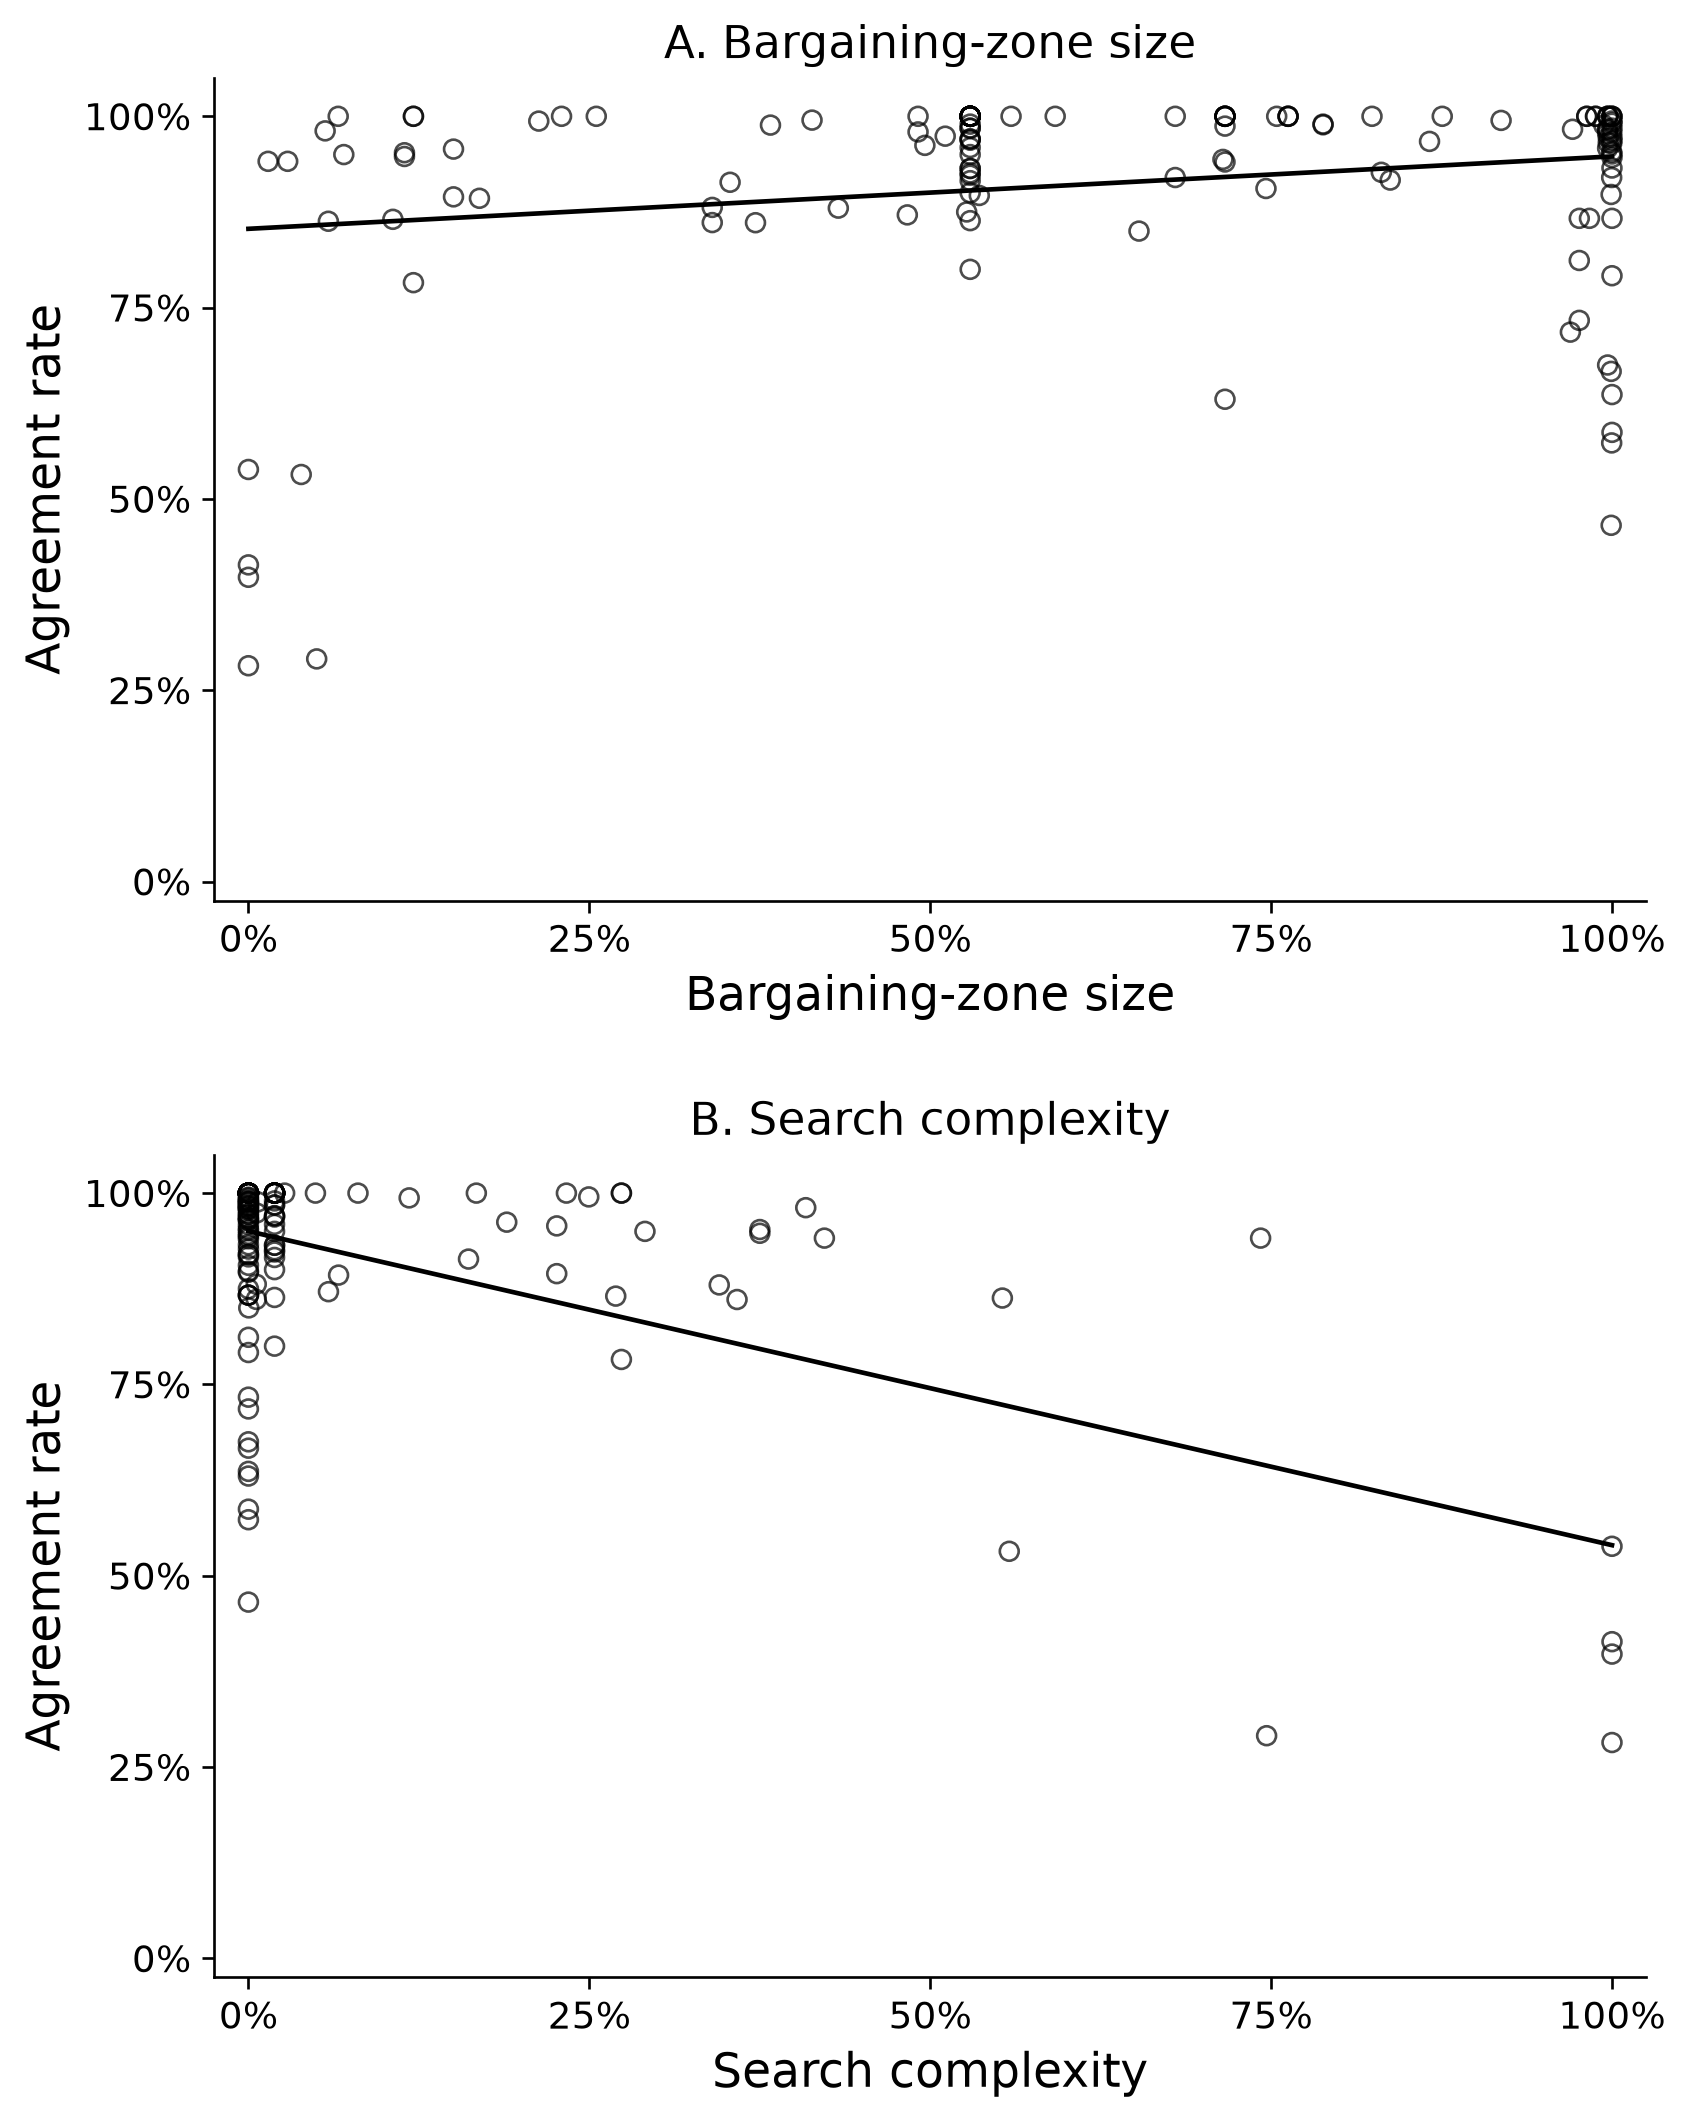

In [6]:
display(Image(filename=str(results / "figures/figure_2.png")))
temporary.cleanup()


## Source inputs and payoff-cell checks

By default the analyses rebuild the coded primary measures and check every payoff cell. To run the same complete workflow from the repository's main folder:

```bash
python scripts/run.py --rebuild-data
```

This runs the complete data construction and the same analyses. Sources and coding decisions are described in [data/README.md](../data/README.md). The original papers and licensed teaching materials are not needed to execute the numerical replication.
